# 🏭 Industrial Rare-Event Breakdown: Pulp-and-Paper Manufacturing Process
## Multivariate Time Series Anomaly Detection & Abrupt Sensor Collapse

### 1. Incident Background
In paper manufacturing mills, large continuous rolls of paper pass through chemical baths, pressing rollers, and high-speed driers. Occasionally, a **sheet break** occurs: the moving paper web snaps. 
* A sheet break is a classic **rare event** (occurring in less than 1% of operational hours).
* Each break causes hours of downtime, machine shutdown, and expensive raw material waste.

### 2. Target Variables ($y$)
* **`y`** (Binary Label): `y = 1` during the rare break event, `y = 0` during normal operation (extreme class imbalance: ~0.67% positives).
* **`x21` / `x4`** (Continuous Process Sensors): Physical tension and flow sensors that experience an **instant cliff drop** down to zero during the breakdown.

### 3. Data Source
* Chitta Ranjan et al. (*arXiv:1809.10717: Dataset: Rare Event Classification in Multivariate Time Series*).
* Contains 18,398 time intervals sampled every 2 minutes across 61 synchronized sensors (`x1` to `x61`).


### 📚 Academic Citations & Benchmark Lineage
* **Primary Paper & Dataset:** Ranjan, C., Mustonen, M., Basu, K., & Sankavaram, C. (2018). *"Dataset: Rare Event Classification in Multivariate Time Series."* arXiv preprint arXiv:1809.10717.
* **Benchmark Context:** Industrial predictive maintenance and multivariate rare-event breakdown classification (<0.7% positive class imbalance).
* **BibTeX Citation:**
```bibtex
@article{ranjan2018dataset,
  title={Dataset: Rare Event Classification in Multivariate Time Series},
  author={Ranjan, Chitta and Mustonen, Mauno and Basu, Kamalika and Sankavaram, Chetan},
  journal={arXiv preprint arXiv:1809.10717},
  year={2018}
}
```

In [1]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('data', exist_ok=True)
print("Environment initialized.")

Environment initialized.


### 4. Data Ingestion & Local Caching

In [2]:
def load_paper_mill_data(cache_dir='data'):
    cache_path = os.path.join(cache_dir, 'pulp_paper_mill_raw.csv')
    
    if os.path.exists(cache_path):
        print(f"Loading paper mill data from cache: {cache_path}")
        df = pd.read_csv(cache_path)
    else:
        print("Downloading raw multivariate dataset from open GitHub repository...")
        url = "https://raw.githubusercontent.com/robertoamansur/rare_event_pred_maintanance/master/processminer-rare-event-mts%20-%20data.csv"
        df = pd.read_csv(url, sep=';')
        df.to_csv(cache_path, index=False)
        print(f"Downloaded and cached {df.shape} records.")
        
    return df

df_raw = load_paper_mill_data()
print(f"Dataset Dimensions: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print(f"Rare Break Events (y=1): {(df_raw['y'] == 1).sum()} ({df_raw['y'].mean()*100:.2f}%)")
df_raw.head()

Loading paper mill data from cache: data/pulp_paper_mill_raw.csv
Dataset Dimensions: 18398 rows, 63 columns
Rare Break Events (y=1): 124 (0.67%)


,time,y,x1,x2,x3,x4,x5,x6,x7,x8,...,x52,x53,x54,x55,x56,x57,x58,x59,x60,x61
0,5/1/99 0:00,0,0.376665,-4.596435,-4.095756,13.497687,-0.118830,-20.669883,0.000732,-0.061114,...,10.091721,0.053279,-4.936434,-24.590146,18.515436,3.473400,0.033444,0.953219,0.006076,0
1,5/1/99 0:02,0,0.475720,-4.542502,-4.018359,16.230659,-0.128733,-18.758079,0.000732,-0.061114,...,10.095871,0.062801,-4.937179,-32.413266,22.760065,2.682933,0.033536,1.090502,0.006083,0
2,5/1/99 0:04,0,0.363848,-4.681394,-4.353147,14.127997,-0.138636,-17.836632,0.010803,-0.061114,...,10.100265,0.072322,-4.937924,-34.183774,27.004663,3.537487,0.033629,1.840540,0.006090,0
3,5/1/99 0:06,0,0.301590,-4.758934,-4.023612,13.161566,-0.148142,-18.517601,0.002075,-0.061114,...,10.104660,0.081600,-4.938669,-35.954281,21.672449,3.986095,0.033721,2.554880,0.006097,0
4,5/1/99 0:08,0,0.265578,-4.749928,-4.333150,15.267340,-0.155314,-17.505913,0.000732,-0.061114,...,10.109054,0.091121,-4.939414,-37.724789,21.907251,3.601573,0.033777,1.410494,0.006105,0


### 5. Preprocessing & Sensor Behavior Analysis

In [3]:
df_proc = df_raw.copy()
df_proc['time'] = pd.to_datetime(df_proc['time'], format='%m/%d/%y %H:%M')
df_proc = df_proc.sort_values('time').reset_index(drop=True)

# Drop static / constant sensors with near-zero variance
sensor_cols = [c for c in df_proc.columns if c.startswith('x')]
stds = df_proc[sensor_cols].std()
static_sensors = stds[stds < 1e-4].index.tolist()
print(f"Static / dead sensors removed: {static_sensors}")
df_proc = df_proc.drop(columns=static_sensors)
sensor_cols = [c for c in sensor_cols if c not in static_sensors]

# Calculate sensor drop delta across y=0 vs y=1
mean_normal = df_proc[df_proc['y'] == 0][sensor_cols].mean()
mean_break = df_proc[df_proc['y'] == 1][sensor_cols].mean()
drop_diff = mean_break - mean_normal
top_drop_sensor = drop_diff.idxmin()
top_spike_sensor = drop_diff.idxmax()

print(f"Sensor with sharpest drop during sheet break: {top_drop_sensor} (Mean shift: {drop_diff[top_drop_sensor]:.3f})")
print(f"Sensor with sharpest spike during sheet break: {top_spike_sensor} (Mean shift: {drop_diff[top_spike_sensor]:.3f})")

# Feature engineering: Rolling 10-step stats for the primary drop sensor
df_proc[f'{top_drop_sensor}_rolling_mean'] = df_proc[top_drop_sensor].rolling(10).mean()
df_proc[f'{top_drop_sensor}_rolling_std'] = df_proc[top_drop_sensor].rolling(10).std()
df_proc[f'{top_drop_sensor}_diff'] = df_proc[top_drop_sensor].diff()

df_proc.head()

Static / dead sensors removed: []
Sensor with sharpest drop during sheet break: x44 (Mean shift: -206.945)
Sensor with sharpest spike during sheet break: x51 (Mean shift: 33.602)


,time,y,x1,x2,x3,x4,x5,x6,x7,x8,...,x55,x56,x57,x58,x59,x60,x61,x44_rolling_mean,x44_rolling_std,x44_diff
0,1999-05-01 00:00:00,0,0.376665,-4.596435,-4.095756,13.497687,-0.118830,-20.669883,0.000732,-0.061114,...,-24.590146,18.515436,3.473400,0.033444,0.953219,0.006076,0,NaN,NaN,NaN
1,1999-05-01 00:02:00,0,0.475720,-4.542502,-4.018359,16.230659,-0.128733,-18.758079,0.000732,-0.061114,...,-32.413266,22.760065,2.682933,0.033536,1.090502,0.006083,0,NaN,NaN,18.74609
2,1999-05-01 00:04:00,0,0.363848,-4.681394,-4.353147,14.127997,-0.138636,-17.836632,0.010803,-0.061114,...,-34.183774,27.004663,3.537487,0.033629,1.840540,0.006090,0,NaN,NaN,-2.25586
3,1999-05-01 00:06:00,0,0.301590,-4.758934,-4.023612,13.161566,-0.148142,-18.517601,0.002075,-0.061114,...,-35.954281,21.672449,3.986095,0.033721,2.554880,0.006097,0,NaN,NaN,-2.43164
4,1999-05-01 00:08:00,0,0.265578,-4.749928,-4.333150,15.267340,-0.155314,-17.505913,0.000732,-0.061114,...,-37.724789,21.907251,3.601573,0.033777,1.410494,0.006105,0,NaN,NaN,-2.43359


### 6. Timeline Visualizations of the Sheet Break Drops

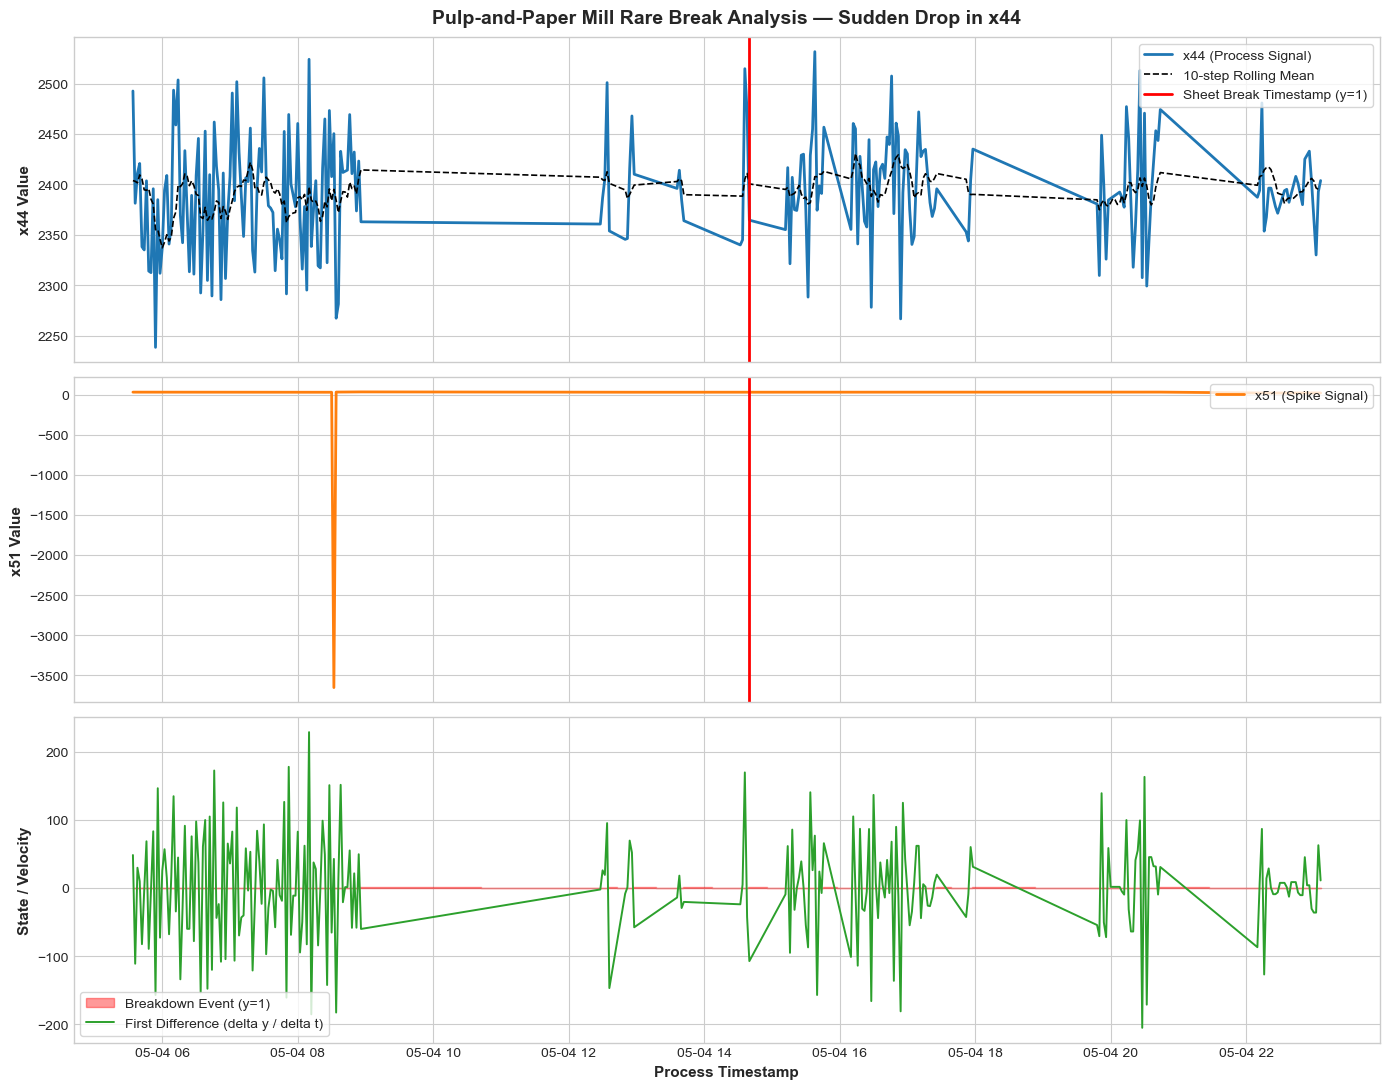

In [4]:
# Pick a specific incident window with consecutive breakdown events
break_indices = df_proc.index[df_proc['y'] == 1].tolist()
sample_event_idx = break_indices[15] # Focus on an illustrative break event
window = 120 # +/- 120 steps (4 hours)
start_idx = max(0, sample_event_idx - window)
end_idx = min(len(df_proc), sample_event_idx + window)

sub_df = df_proc.iloc[start_idx:end_idx].copy()
event_time = df_proc.loc[sample_event_idx, 'time']

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

# 1. Primary Drop Sensor Response
axes[0].set_title(f"Pulp-and-Paper Mill Rare Break Analysis — Sudden Drop in {top_drop_sensor}", 
                  fontsize=14, fontweight='bold', pad=10)
axes[0].plot(sub_df['time'], sub_df[top_drop_sensor], color='#1f77b4', lw=2.0, label=f'{top_drop_sensor} (Process Signal)')
axes[0].plot(sub_df['time'], sub_df[f'{top_drop_sensor}_rolling_mean'], color='black', lw=1.2, ls='--', label='10-step Rolling Mean')
axes[0].axvline(event_time, color='red', lw=2, ls='-', label='Sheet Break Timestamp (y=1)')
axes[0].set_ylabel(f"{top_drop_sensor} Value", fontsize=11, fontweight='bold')
axes[0].legend(loc='upper right', frameon=True)

# 2. Sudden Spike Sensor (Counter-Pressure or Valve Surge)
axes[1].plot(sub_df['time'], sub_df[top_spike_sensor], color='#ff7f0e', lw=2.0, label=f'{top_spike_sensor} (Spike Signal)')
axes[1].axvline(event_time, color='red', lw=2, ls='-')
axes[1].set_ylabel(f"{top_spike_sensor} Value", fontsize=11, fontweight='bold')
axes[1].legend(loc='upper right', frameon=True)

# 3. Rare Break Indicator (Target y) and Velocity
axes[2].fill_between(sub_df['time'], 0, sub_df['y'], color='red', alpha=0.4, step='mid', label='Breakdown Event (y=1)')
axes[2].plot(sub_df['time'], sub_df[f'{top_drop_sensor}_diff'], color='#2ca02c', lw=1.4, label='First Difference (delta y / delta t)')
axes[2].set_ylabel("State / Velocity", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Process Timestamp", fontsize=11, fontweight='bold')
axes[2].legend(loc='lower left', frameon=True)

plt.tight_layout()
plt.savefig('data/paper_mill_break_timeline.png', dpi=300)
plt.show()

### 7. Statistical Regime Shift: Normal Operation vs. Breakdown

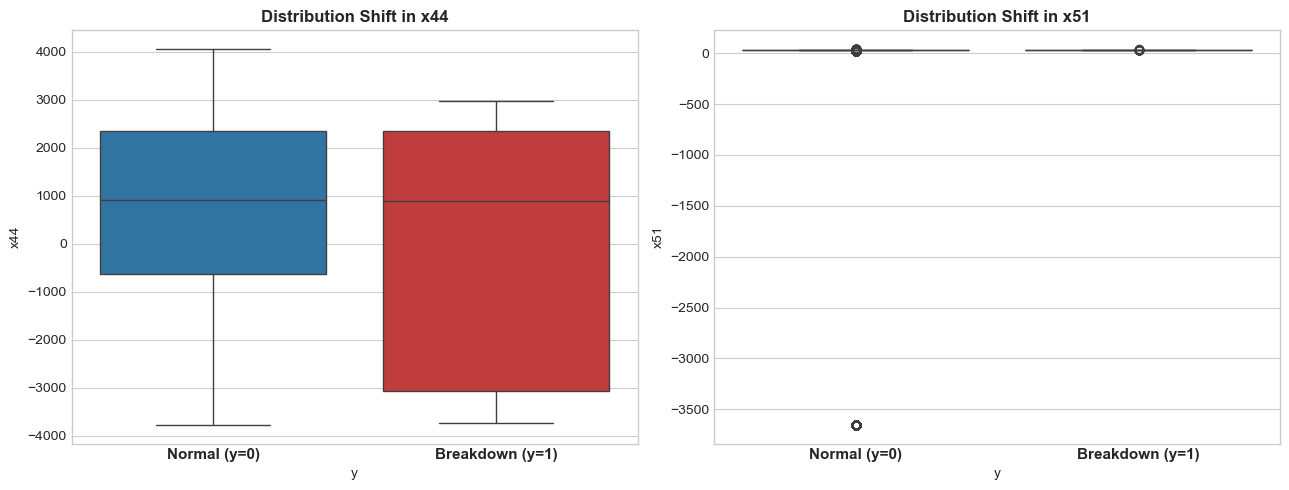

Processed paper mill dataset saved to data/pulp_paper_mill_processed.csv


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Distribution of Top Drop Sensor
sns.boxplot(x='y', y=top_drop_sensor, data=df_proc, ax=ax1, palette=['#1f77b4', '#d62728'], hue='y', legend=False)
ax1.set_xticks([0, 1])
ax1.set_xticklabels(['Normal (y=0)', 'Breakdown (y=1)'], fontsize=11, fontweight='bold')
ax1.set_title(f"Distribution Shift in {top_drop_sensor}", fontsize=12, fontweight='bold')

# Distribution of Top Spike Sensor
sns.boxplot(x='y', y=top_spike_sensor, data=df_proc, ax=ax2, palette=['#1f77b4', '#d62728'], hue='y', legend=False)
ax2.set_xticks([0, 1])
ax2.set_xticklabels(['Normal (y=0)', 'Breakdown (y=1)'], fontsize=11, fontweight='bold')
ax2.set_title(f"Distribution Shift in {top_spike_sensor}", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Export clean dataset
df_proc.to_csv('data/pulp_paper_mill_processed.csv', index=False)
print("Processed paper mill dataset saved to data/pulp_paper_mill_processed.csv")